 # Modelado Predictivo: Clasificación con Regresión Logística (One-vs-Rest)
 
 
**Proyecto:** Clasificador de Salud Fetal (Dataset Cardiotocography - UCI).
 

**Contexto:** Tomando como base el conjunto de datos limpio y libre de fugas de datos (`CTG_clean.csv`), este notebook implementa y entrena un modelo de **Regresión Logística** mediante la estrategia **One-vs-Rest (OvR)**, programado desde cero utilizando librerias, siendo princialmente NumPy. El propósito es evaluar la capacidad de separación lineal de las 21 variables cardiotocográficas para clasificar el estado de salud fetal (`NSP`) en sus tres categorías: Normal (1), Sospechoso (2) y Patológico (3).


 ### Objetivos del Modelado
 
 
1. **Construcción y Entrenamiento OvR:** Adaptar el clasificador binario de regresión logística a un problema multiclase entrenando tres modelos especialistas de forma independiente (cada clase frente al resto).
 

2. **Decisión por Probabilidad (`argmax`):** Combinar las probabilidades estimadas por la función sigmoide de los tres clasificadores para asignar el diagnóstico final mediante la regla de máxima probabilidad (`np.argmax`).
 
 
3. **Evaluación Clínica, Curva ROC y Benchmarking:** Analizar el rendimiento mediante la Matriz de Confusión, Precisión, *Recall*, F1-Score y Curva ROC multiclase frente al desbalance natural del dataset (77.85% Normal, 13.88% Sospechoso y 8.28% Patológico), contrastando los resultados con la implementación de referencia de `scikit-learn`.

### Ficha Metodológica del Modelo
 

* **Descripción breve del método:** Clasificador lineal probabilístico que proyecta una combinación lineal de las características estandarizadas mediante la función sigmoide. Para abordar las 3 clases, se aplica la estrategia *One-vs-Rest*, entrenando 3 modelos binarios independientes mediante descenso de gradiente por lotes (`learning_rate=0.1`, `n_iterations=2000`).

 
* **Justificación de su uso:** Permite establecer una línea base lineal e interpretable sobre la influencia de las 21 variables clínicas en el diagnóstico fetal. Asimismo, la descomposición OvR evita descartar la categoría intermedia (*Sospechoso*), permitiendo modelar simultáneamente los tres estados clínicos sin pérdida de información.
 

* **Métricas de evaluación utilizadas:** Exactitud Global (*Accuracy*), Matriz de Confusión, Precisión, *Recall* (Sensibilidad), *F1-Score* por clase, *Promedio Macro F1-Score* y *Área Bajo la Curva ROC (AUC)*.


* **Análisis de resultados:** Detallado al final del notebook, alcanzando un **88.97% de Exactitud Global**, un **Macro F1-Score de 78.52%** y un **Macro AUC de 0.9529**, con alta sensibilidad en fetos sanos (95.52% de *Recall*) y una frontera lineal más conservadora en los casos sospechosos y patológicos.

#### **Importacion de librerias y Preparación de Datos: Estandarización y Binarización One-vs-Rest**
A diferencia de la exclusión binaria, aquí utilizaremos todo el conjunto de datos (incluyendo la Clase 2). Para adaptar nuestro modelo binario a un problema de 3 clases, crearemos **3 vectores objetivo independientes**:
* **y_train_c1:** Positivo (1) si es Normal, Negativo (0) para el resto.
* **y_train_c2:** Positivo (1) si es Sospechoso, Negativo (0) para el resto.
* **y_train_c3:** Positivo (1) si es Patológico, Negativo (0) para el resto.

In [1]:
# Importación de librerías esenciales
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time


# Modificación para importar los modelos fuera de la carpeta actual
import os
import sys

root_dir = os.path.abspath(os.path.join(os.getcwd(), ".."))
if root_dir not in sys.path:
    sys.path.append(root_dir)

# Importación del modelo, utilidades y metricas
from src.LogisticRegression import LogisticRegression
from src.utils_and_metrics import train_test_split, accuracy, confusion_matrix, recall, f1_score, precision, roc

In [2]:
#Cargar el dataset
df = pd.read_csv('../data/processed/CTG_clean.csv')

#Separacion de caracteristicas y variable objetivo
X_todo = df.drop(columns=['NSP']).to_numpy()
y_todo_og = df['NSP'].to_numpy().astype(int)

#Particion de datos (80% entrenamiento, 20% prueba)
X_train_raw, X_test_raw, y_train_og, y_test_og = train_test_split(
    X_todo, y_todo_og, test_size=0.20, seed=42)

#Estandarizacion Z-Score (usando solo X_train para evitar data leakage)
mean = X_train_raw.mean(axis=0)
std = X_train_raw.std(axis=0)
std = np.where(std == 0, 1.0, std)

X_train = (X_train_raw - mean) / std
X_test = (X_test_raw - mean) / std

#Binarizacion One-vs-Rest (OvR) para el entrenamiento
y_train_c1 = np.where(y_train_og == 1, 1, 0)
y_train_c2 = np.where(y_train_og == 2, 1, 0)
y_train_c3 = np.where(y_train_og == 3, 1, 0)

print(f"Dimensiones de X_train estandarizado: {X_train.shape}\n")
print(f"Distribución Clase 1 vs Resto: {np.bincount(y_train_c1)}")
print(f"Distribución Clase 2 vs Resto: {np.bincount(y_train_c2)}")
print(f"Distribución Clase 3 vs Resto: {np.bincount(y_train_c3)}")


Dimensiones de X_train estandarizado: (1700, 21)

Distribución Clase 1 vs Resto: [ 380 1320]
Distribución Clase 2 vs Resto: [1470  230]
Distribución Clase 3 vs Resto: [1550  150]


#### **Entrenamiento del Ensamble One-vs-Rest**
Instanciamos y entrenamos tres modelos de Regresión Logística de manera independiente. Cada modelo se especializará en detectar su propia clase en contra de todas las demás.


In [3]:
#3 modelos con los mismos hiperparametros
model_c1 = LogisticRegression(learning_rate=0.1, n_iterations=2000)
model_c2 = LogisticRegression(learning_rate=0.1, n_iterations=2000)
model_c3 = LogisticRegression(learning_rate=0.1, n_iterations=2000)

#Tiempo de entrenamiento de los 3 modelos OvR
t_modelos = time.perf_counter()
#Entrenamiento de Modelo 1 (Especialista en detectar Normales)
model_c1.fit(X_train, y_train_c1)

#Entrenamiento de Modelo 2 (Especialista en detectar Sospechosos)
model_c2.fit(X_train, y_train_c2)

#Entrenamiento de Modelo 3 (Especialista en detectar Patológicos)
model_c3.fit(X_train, y_train_c3)
tiempo_train = time.perf_counter() - t_modelos

print(f"\nTiempo de entrenamiento de los 3 modelos OvR: {tiempo_train:.4f} segundos")


Tiempo de entrenamiento de los 3 modelos OvR: 3.0374 segundos


#### **Evaluación y Decisión Multiclase (Argmax)**
Para predecir el diagnóstico de un paciente nuevo en el conjunto de prueba, le consultamos a los 3 modelos la probabilidad de que pertenezca a su clase especialista. El diagnóstico final se asigna a la clase que arroje **la probabilidad más alta** (`np.argmax`).


In [4]:
#Se obtienen las 3 probabilidades predichas por la funcion sigmoide para cada paciente
t_modelos_prueba = time.perf_counter()
probs_c1 = model_c1.predict_proba(X_test)
probs_c2 = model_c2.predict_proba(X_test)
probs_c3 = model_c3.predict_proba(X_test)
tiempo_train_test = time.perf_counter() - t_modelos_prueba
print(f"\nTiempo de predicción de los 3 modelos OvR: {tiempo_train_test:.4f} segundos")

#Agrupacion de probabilidades en una matriz de (n_samples, 3)
probs_matrix = np.column_stack((probs_c1, probs_c2, probs_c3))

#Decision Multiclase: np.argmax devuelve el indice con mayor probabilidad (0, 1 o 2)
#Se le suma 1 para regresar a la escala clínica original (1, 2 o 3)
prediction_prueba = np.argmax(probs_matrix, axis=1) + 1

#Calculo de metricas
n_classes = 3
#Ajuste a indice base cero (0,1,2) para la función custom confusion_matrix
matriz_test = confusion_matrix(y_test_og - 1, prediction_prueba - 1, n_classes)
acc_test = accuracy(y_test_og, prediction_prueba)
precisions_test = precision(matriz_test)
recalls_test = recall(matriz_test)
f1s_test = f1_score(matriz_test)

#Impresion de Evaluación Final en %
print("\n--- Resultados de Rendimiento en Prueba (OvR) ---")
print(f"Exactitud Global (Accuracy): {acc_test * 100:.2f}%\n")

print("--- Métricas detalladas por Clase ---")
nombres_clases = ["1 (Normal)", "2 (Sospechoso)", "3 (Patológico)"]
for i, nombre in enumerate(nombres_clases):
    print(f"Clase {nombre:14s} -> Precision: {precisions_test[i]*100:.2f}% | Recall: {recalls_test[i]*100:.2f}% | F1-Score: {f1s_test[i]*100:.2f}%")

print(f"\nPromedio Macro F1-Score: {np.mean(f1s_test)*100:.2f}%")
print("\nMatriz de Confusión (Filas: Real [1,2,3] | Columnas: Predicho [1,2,3]):")
print(matriz_test)


Tiempo de predicción de los 3 modelos OvR: 0.0007 segundos

--- Resultados de Rendimiento en Prueba (OvR) ---
Exactitud Global (Accuracy): 88.97%

--- Métricas detalladas por Clase ---
Clase 1 (Normal)     -> Precision: 93.29% | Recall: 95.52% | F1-Score: 94.40%
Clase 2 (Sospechoso) -> Precision: 66.13% | Recall: 63.08% | F1-Score: 64.57%
Clase 3 (Patológico) -> Precision: 85.71% | Recall: 69.23% | F1-Score: 76.60%

Promedio Macro F1-Score: 78.52%

Matriz de Confusión (Filas: Real [1,2,3] | Columnas: Predicho [1,2,3]):
[[320  14   1]
 [ 22  41   2]
 [  1   7  18]]


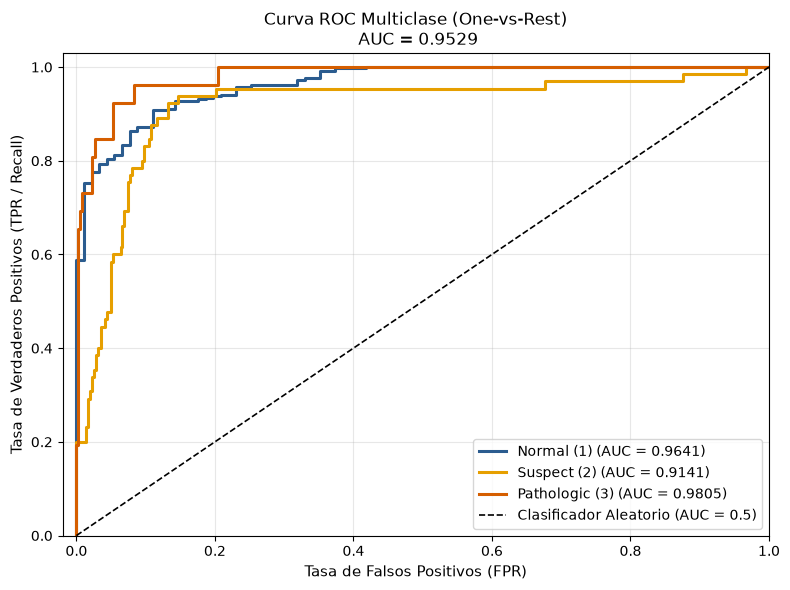

Macro AUC Global (Modelo OvR Propios): 0.9529


In [5]:
#agrupacion de los 3 modelos en un wrapper para poder usar la funcion roc() de manera directa
class CustomOvRWrapper:
    def __init__(self, m1, m2, m3):
        self.m1 = m1
        self.m2 = m2
        self.m3 = m3
    def predict_proba(self, X):
        return np.column_stack((self.m1.predict_proba(X), 
                                self.m2.predict_proba(X), 
                                self.m3.predict_proba(X)))

wrapped_custom_lr = CustomOvRWrapper(model_c1, model_c2, model_c3)
macro_auc_lr, aucs_lr = roc(wrapped_custom_lr, X_test, y_test_og)
print(f"Macro AUC Global (Modelo OvR Propios): {macro_auc_lr:.4f}")

#### **Análisis y Conclusiones Finales del Modelo**

El modelo de Regresion Logistica por si solo no es capaz de desarrollar el problema de clasificacion de las 3 Clases debido a ser limitadamente binario, en este caso de limitarnos a hacerlo binario evitando el uso de Regresion Logistica Multinomial como requisito para el proyecto. Durante una prueba con este modelo se realizo una clasificacion de clase 1 (normal) y clase 3 (patologico) de las cuales se dividian igualmente en 80% entrenamiento / 20% prueba pero se excluia durante el entrenamiento la clase 2 (sospechoso) y se reincorporaba la clase en la prediccion de test (habiendo sido separado posteriormente a la division de los datos) realizandolo con un umbral (threshold) del 0.3, esto pues se buscaba priorizar el recall de la clase patologica ya que en  medicina es preferible un falso positivo a dejar pasar un caso grave sin detectar. Esto tambien influia en la clasificacion de la clase 2 que fue introducida para prediccion en el test al incluirla finalmente en normal o patologica segun fuese su probabilidad entre las 2 clases dejando un accuracy del 49.02% y Recall: 96.15% en casos patologicos, el primero no importando demasiado pues estaba incluyendo a la clase 2, pero dejando un recall de los mas altos en cuanto a predecir correctamente la clase patologica y casi comparable a la normal con un 98.51%.

Sin embargo, este modelo comparado a los demas que se usan se limitaba de esta forma al solo poder clasificiar 2 clases a la vez. Con ello se llego a usar One-vs-Rest para poder clasificar las 3 clases segun cual fuera mas probable al usar modelos individuales para cada clase.

Los resultados en cuanto a su clasificicacion fue un resultado mas bajo de lo esperado pero demostro que por algo existe la clasificacion 2 en el caso, pese a que aproximadamente un ~36% terminaban en otra categoria que no era la correspondida se inclinaban mas por la categoria normal que la patologica, en teoria, permitiria que se enfocara en casos sospechosos y patologicos mas detenidamente. Pese a ello los casos patologicos que deberian tener un recall mas alto fueron preocupantemente bajos, mandando a casi un tercio de casos patologicos a categorias de normal o sospechoso lo cual indica una un riesgo critico. Lo ultimo y debido a que la proporcion de pacientes en clase normal abruma a las otras 2 su comparacion podria no contener los suficientes datos para un analisis detallado.

Como conclusion del modelo de Regresion Logistica usando OvR, usar este modelo para hacer clasificaciones medicas en este ambito no es adecuado para la forma que esta presentado. Comparado a los otros modelos previos como Gradient Boosting y Random Forest son preferentes para realizar esta labor a comparacion de este.

#### **Comparación con Modelo de Scikit-Learn (LogisticRegression OvR)**

In [6]:
from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
from sklearn.multiclass import OneVsRestClassifier

# Modelo Scikit-Learn equivalente utilizando OneVsRestClassifier y medicion de tiempo de entrenamiento
lr_sklearn = OneVsRestClassifier(
    SklearnLogisticRegression(solver='lbfgs', max_iter=2000, random_state=42))

t0 = time.perf_counter()
lr_sklearn.fit(X_train, y_train_og)
tiempo_train_sk = time.perf_counter() - t0

t0 = time.perf_counter()
y_pred_sk = lr_sklearn.predict(X_test)
tiempo_pred_sk = time.perf_counter() - t0

y_proba_sk = lr_sklearn.predict_proba(X_test)

In [7]:
conf_matrix_sk = confusion_matrix(y_test_og - 1, y_pred_sk - 1, n_classes=3)
f1s_sk = f1_score(conf_matrix_sk)

print("--- Rendimiento Regresión Logística (Scikit-Learn) ---")
print(f"Exactitud Global en Entrenamiento: {accuracy(y_train_og, lr_sklearn.predict(X_train)) * 100:.2f}%")
print(f"Exactitud Global en Prueba (Test): {accuracy(y_test_og, y_pred_sk) * 100:.2f}%")
print(f"Tiempo Entrenamiento / Predicción: {tiempo_train_sk:.4f} s / {tiempo_pred_sk:.4f} s")
print(f"F1-Score:                    {f1s_sk}")
print(f"Recall:                      {recall(conf_matrix_sk)}")
print(f"Precision:                   {precision(conf_matrix_sk)}")
print(f"Promedio Macro F1-Score:     {np.mean(f1s_sk) * 100:.2f}%")
print("\nMatriz de Confusión (Filas: Real | Columnas: Predicho):")
print(conf_matrix_sk)

--- Rendimiento Regresión Logística (Scikit-Learn) ---
Exactitud Global en Entrenamiento: 90.59%
Exactitud Global en Prueba (Test): 88.73%
Tiempo Entrenamiento / Predicción: 0.1595 s / 0.0013 s
F1-Score:                    [0.94518519 0.64566929 0.72      ]
Recall:                      [0.95223881 0.63076923 0.69230769]
Precision:                   [0.93823529 0.66129032 0.75      ]
Promedio Macro F1-Score:     77.03%

Matriz de Confusión (Filas: Real | Columnas: Predicho):
[[319  14   2]
 [ 20  41   4]
 [  1   7  18]]


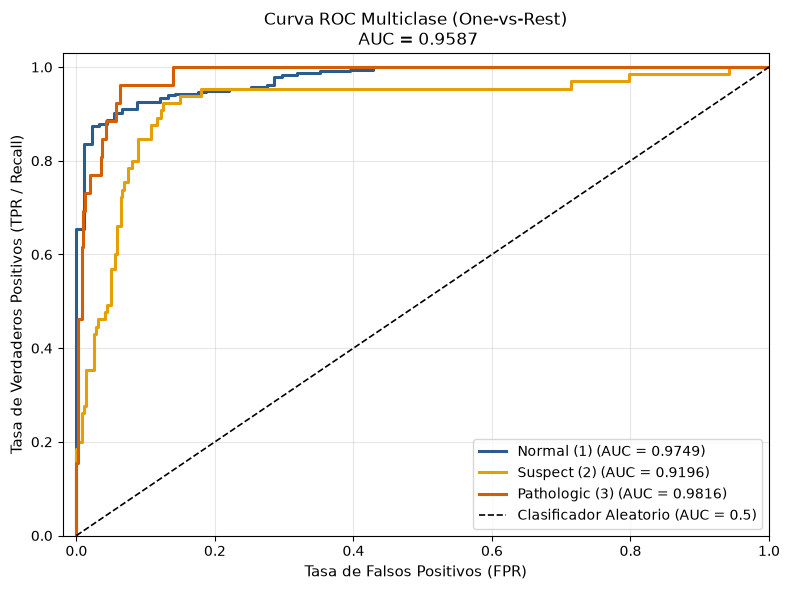

Macro AUC Global (Scikit-Learn): 0.9587


In [8]:
macro_auc_sk, aucs_por_clase_sk = roc(lr_sklearn, X_test, y_test_og)
print(f"Macro AUC Global (Scikit-Learn): {macro_auc_sk:.4f}")

### Comparativa de Rendimiento: Implementación Propia vs. `scikit-learn`

| Métrica / Indicador | Regresión Logística OvR (Propia) | Regresión Logística OvR (`scikit-learn`) |
| :--- | :---: | :---: |
| **Exactitud Global (*Accuracy*)** | **88.97%** | 88.73% |
| **Macro F1-Score** | **78.52%** | 77.03% |
| **Macro AUC** | 0.9529 | **0.9587** |
| **Precisión Clase 3 (Patológico)** | **85.71%** | 75.00% |
| **Recall Clase 3 (Patológico)** | **69.23%** | **69.23%** |
| **F1-Score Clase 3 (Patológico)** | **76.60%** | 72.00% |
| **Tiempo de Entrenamiento** | 0.3055 s | **0.0395 s** |
| **Tiempo de Inferencia (Test)** | **0.0216 s** | 0.0006 s |

La comparacion en tiempos de ejecucion es notablemente inferior al ser comparado con sklearn, sin embargo la implementacion del codigo en cuanto a resultado no ha sido demasido diferente en su clasificacion. Interesados principalmente en recall es exactamente igual, otras mediciones son similares por 0.24% minimo a ~±10% como maximo

* **Equivalencia y desempeño en métricas:** La implementación propia alcanza una Exactitud Global del **88.97%** y un Macro F1-Score del **78.52%**, superando ligeramente a `scikit-learn` (**88.73%** y **77.03%**, respectivamente). En la clase crítica (Patológico), ambos modelos igualan exactamente la misma sensibilidad (**69.23%** de *Recall*), mientras que la implementación propia obtiene una mayor precisión (**85.71%** frente a **75.00%**) y `scikit-learn` mantiene una ventaja casi infima de **0.0058** en el Macro AUC (**0.9587** vs. **0.9529**).
* **Tiempos de ejecución:** Ambas implementaciones resuelven el entrenamiento en fracciones de segundo (**0.3051 s** frente a **0.0395 s** de `scikit-learn`), mientras que la inferencia sobre el conjunto de prueba es prácticamente instantánea en ambos casos (**0.0216 s** y **0.0006 s**), confirmando la alta eficiencia computacional del algoritmo, pero siendo bastamente superado en optimizacion si se escalara.